In [9]:
import numpy as np
from sommerfeld_mdm.sommerfeld import sommerfeld
from sommerfeld_mdm.mdm import mdm_quintupletQ0S0
import matplotlib.pyplot as plt

v_rel = 0.001
Mw = 80.379

masses = np.logspace(3, np.log10(20000), 200)
S3_vals = np.zeros(len(masses))

for M in masses:
    p = M * v_rel / 2
    x_inf = 10.0 * p / Mw
    V_inf, V_eff, Gamma = mdm_quintupletQ0S0(M)
    T = sommerfeld(
        M=M,
        v_rel=v_rel,
        V_inf=V_inf,
        V_eff=V_eff,
        x_inf=x_inf
    )
    T_conj = T.conj().T
    S3_vals[np.where(masses == M)] = (T_conj @ Gamma @ T)[2, 2].real / Gamma[2, 2]
    print(f"Mass: {M:.2f} GeV, S3: {S3_vals[np.where(masses == M)][0]:.4f}")



Mass: 1000.00 GeV, S3: 103.2909
Mass: 1015.17 GeV, S3: 94.7633
Mass: 1030.57 GeV, S3: 87.7010
Mass: 1046.20 GeV, S3: 81.8248
Mass: 1062.07 GeV, S3: 76.9248
Mass: 1078.17 GeV, S3: 72.8415
Mass: 1094.53 GeV, S3: 69.4530
Mass: 1111.13 GeV, S3: 66.6660
Mass: 1127.98 GeV, S3: 64.4098
Mass: 1145.09 GeV, S3: 62.6317
Mass: 1162.46 GeV, S3: 61.2940
Mass: 1180.09 GeV, S3: 60.3721
Mass: 1197.99 GeV, S3: 59.8534
Mass: 1216.16 GeV, S3: 59.7369
Mass: 1234.61 GeV, S3: 60.0334
Mass: 1253.34 GeV, S3: 60.7671
Mass: 1272.35 GeV, S3: 61.9776
Mass: 1291.65 GeV, S3: 63.7231
Mass: 1311.24 GeV, S3: 66.0864
Mass: 1331.13 GeV, S3: 69.1823
Mass: 1351.32 GeV, S3: 73.1704
Mass: 1371.81 GeV, S3: 78.2733
Mass: 1392.62 GeV, S3: 84.8058
Mass: 1413.74 GeV, S3: 93.2227
Mass: 1435.19 GeV, S3: 104.1970
Mass: 1456.95 GeV, S3: 118.7573
Mass: 1479.05 GeV, S3: 138.5378
Mass: 1501.49 GeV, S3: 166.2625
Mass: 1524.26 GeV, S3: 206.7532
Mass: 1547.38 GeV, S3: 269.2270
Mass: 1570.85 GeV, S3: 373.1848
Mass: 1594.68 GeV, S3: 566.1310

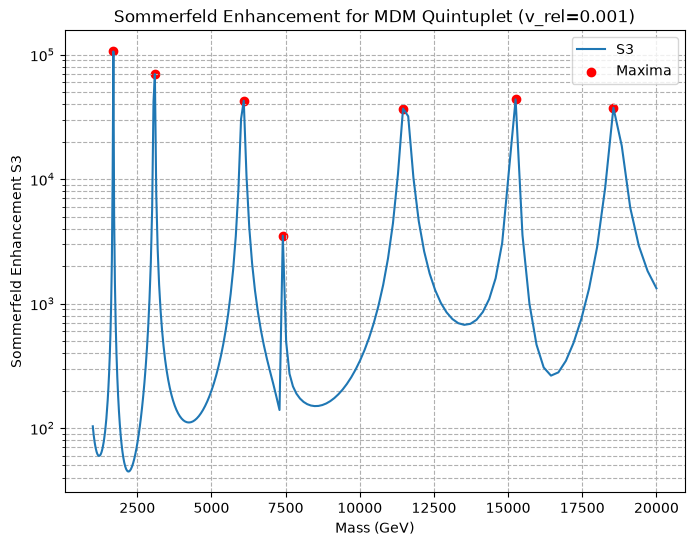

In [13]:
# Identify the three maximum Sommerfeld factors in the three different ranges
S3_max1 = np.max(S3_vals[(1000 <= masses) & (masses <= 2500)])
S3_max2 = np.max(S3_vals[(2500 < masses) & (masses <= 5000)])
S3_max3 = np.max(S3_vals[(5000 < masses) & (masses <= 7000)])
S3_max4 = np.max(S3_vals[(7000 < masses) & (masses <= 10000)])
S3_max5 = np.max(S3_vals[(10000 <= masses) & (masses <= 12000)])
S3_max6 = np.max(S3_vals[(14000 < masses) & (masses < 16000)])
S3_max7 = np.max(S3_vals[(17000 < masses) & (masses < 20000)])

mass_max1 = masses[(1000 <= masses) & (masses <= 2500)][np.argmax(S3_vals[(1000 <= masses) & (masses <= 2500)])]
mass_max2 = masses[(2500 < masses) & (masses <= 5000)][np.argmax(S3_vals[(2500 < masses) & (masses <= 5000)])]
mass_max3 = masses[(5000 < masses) & (masses <= 7000)][np.argmax(S3_vals[(5000 < masses) & (masses <= 7000)])]
mass_max4 = masses[(7000 < masses) & (masses <= 10000)][np.argmax(S3_vals[(7000 < masses) & (masses <= 10000)])]
mass_max5 = masses[(10000 <= masses) & (masses <= 12000)][np.argmax(S3_vals[(10000 <= masses) & (masses <= 12000)])]
mass_max6 = masses[(14000 < masses) & (masses < 16000)][np.argmax(S3_vals[(14000 < masses) & (masses < 16000)])]
mass_max7 = masses[(17000 < masses) & (masses < 20000)][np.argmax(S3_vals[(17000 < masses) & (masses < 20000)])]


plt.figure(figsize=(8, 6))
plt.plot(masses, S3_vals, label="S3")
plt.scatter([mass_max1, mass_max2, mass_max3, mass_max4, mass_max5, mass_max6, mass_max7], [S3_max1, S3_max2, S3_max3, S3_max4, S3_max5, S3_max6, S3_max7], color='red', label='Maxima')
plt.yscale("log")
plt.xlabel("Mass (GeV)")
plt.ylabel("Sommerfeld Enhancement S3")
plt.title(f"Sommerfeld Enhancement for MDM Quintuplet (v_rel={v_rel})")
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()


In [14]:
print(f"Maximum S3 in range 1000-2500 GeV: {S3_max1:.4f} at mass {mass_max1:.2f} GeV")
print(f"Maximum S3 in range 2500-5000 GeV: {S3_max2:.4f} at mass {mass_max2:.2f} GeV")
print(f"Maximum S3 in range 5000-7000 GeV: {S3_max3:.4f} at mass {mass_max3:.2f} GeV")
print(f"Maximum S3 in range 7000-10000 GeV: {S3_max4:.4f} at mass {mass_max4:.2f} GeV")
print(f"Maximum S3 in range 10000-12000 GeV: {S3_max5:.4f} at mass {mass_max5:.2f} GeV")
print(f"Maximum S3 in range 14000-16000 GeV: {S3_max6:.4f} at mass {mass_max6:.2f} GeV")
print(f"Maximum S3 in range 17000-20000 GeV: {S3_max7:.4f} at mass {mass_max7:.2f} GeV")


Maximum S3 in range 1000-2500 GeV: 106292.2530 at mass 1693.65 GeV
Maximum S3 in range 2500-5000 GeV: 70020.8526 at mass 3092.70 GeV
Maximum S3 in range 5000-7000 GeV: 42743.2470 at mass 6088.93 GeV
Maximum S3 in range 7000-10000 GeV: 3516.2895 at mass 7405.13 GeV
Maximum S3 in range 10000-12000 GeV: 36972.0101 at mass 11458.56 GeV
Maximum S3 in range 14000-16000 GeV: 43841.8946 at mass 15252.78 GeV
Maximum S3 in range 17000-20000 GeV: 37538.9584 at mass 18549.87 GeV


In [26]:
Smax = np.array([S3_max1, S3_max2, S3_max3, S3_max4, S3_max5, S3_max6, S3_max7])
Mmax = np.array([mass_max1, mass_max2, mass_max3, mass_max4, mass_max5, mass_max6, mass_max7])
Mmax[4]

np.float64(11458.557442061476)

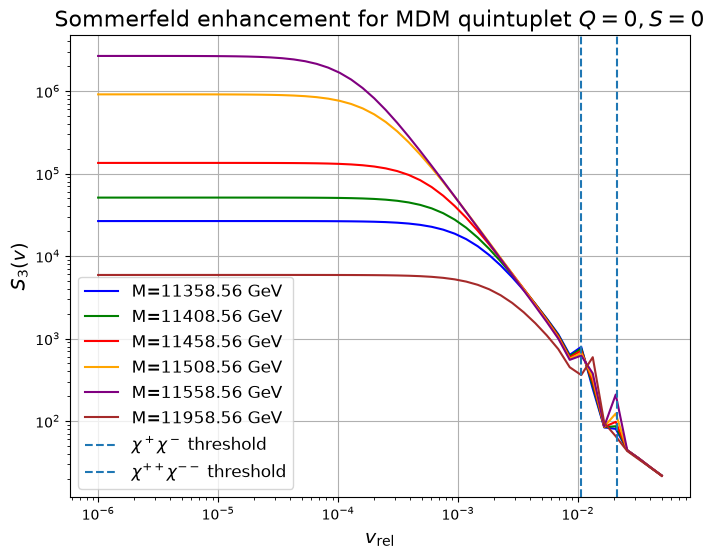

In [ ]:
# Select the mass corresponding to the maximum S3 in the range 10000-12000 GeV
Mtest = np.array([Mmax[4] - 100,Mmax[4] - 50,Mmax[4], Mmax[4] + 50, Mmax[4] + 100,Mmax[4] + 500])  # Test masses around the maximum

delta = 0.167
Mw = 80.379

npoints = 50
v_rel = np.logspace(-6, np.log10(0.05), npoints)
S3_list = []

for M in Mtest:  
    for v in v_rel:
        p = M * v / 2
        x_inf = 10.0 * p / Mw

        V_inf, V_eff, Gamma = mdm_quintupletQ0S0(M)
        T = sommerfeld(
            M=M,
            v_rel=v,
            V_inf=V_inf,
            V_eff=V_eff,
            x_inf=x_inf
        )
        T_conj = T.conj().T
        S3 = (T_conj @ Gamma @ T)[2, 2].real / Gamma[2, 2]
        S3_list.append(S3)

    
S3_list = np.array(S3_list)

v_threshold_2 = np.sqrt(8 * delta / M)
v_threshold_1 = np.sqrt(32 * delta / M)



In [30]:
v_KD = np.sqrt(6 * 0.01 / Mtest)  # Kinetic decoupling velocity at T=10 MeV

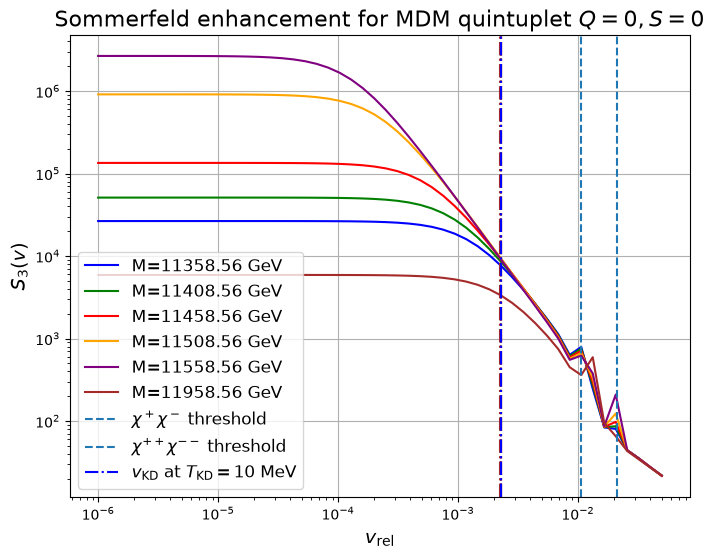

In [35]:
plt.figure(figsize=(8,6))
plt.loglog(v_rel, S3_list[0:npoints], label=f"M={Mtest[0]:.2f} GeV", color='blue')
plt.loglog(v_rel, S3_list[1*npoints:2*npoints], label=f"M={Mtest[1]:.2f} GeV", color='green')
plt.loglog(v_rel, S3_list[2*npoints:3*npoints], label=f"M={Mtest[2]:.2f} GeV", color='red')
plt.loglog(v_rel, S3_list[3*npoints:4*npoints], label=f"M={Mtest[3]:.2f} GeV", color='orange')
plt.loglog(v_rel, S3_list[4*npoints:5*npoints], label=f"M={Mtest[4]:.2f} GeV", color='purple')
plt.loglog(v_rel, S3_list[5*npoints:6*npoints], label=f"M={Mtest[5]:.2f} GeV", color='brown')
plt.xlabel(r"$v_\mathrm{rel}$", fontsize=14)
plt.ylabel(r"$S_3(v)$", fontsize=14)
plt.title(r"Sommerfeld enhancement for MDM quintuplet $Q=0, S=0$", fontsize=16)
plt.axvline(v_threshold_2, linestyle="--",label=r"$\chi^+\chi^-$ threshold")
plt.axvline(v_threshold_1, linestyle="--",label=r"$\chi^{++}\chi^{--}$ threshold")

plt.axvline(v_KD[1], linestyle="-.", color='green')
plt.axvline(v_KD[2], linestyle="-.", color='red')
plt.axvline(v_KD[3], linestyle="-.", color='orange')
plt.axvline(v_KD[4], linestyle="-.", color='purple')
plt.axvline(v_KD[5], linestyle="-.", color='brown')
plt.axvline(v_KD[0], linestyle="-.", color='blue', label=r"$v_\mathrm{KD}$ at $T_\mathrm{KD}=10$ MeV")

plt.legend(fontsize=12)
plt.grid()
plt.show()

In [24]:
S3_list[50:100]

array([], dtype=float64)